# **Mejora 3: *Self-Attention* global 

## **0. Introducción y objetivo**

Este notebook completa la comparativa del punto **2.2** de `explicacion_mejoras.ipynb`. Partimos exactamente del mismo **baseline** que en `mejora2.ipynb`:

- En **`mejora2.ipynb`** probamos **CBAM** en `16x16` y `8x8`.
- En **`mejora3.ipynb`** probamos **Self-Attention** (estilo Transformer) en la resolución **`8x8`**, tanto en el encoder como en el decoder.

### **Por qué probamos *Self-Attention* en $8 \times 8$**

Como explicamos en `mejora2.ipynb`, CBAM sigue limitado a una convolución local $7 \times 7$ y no puede relacionar extremos opuestos de la imagen. **Self-Attention**, en cambio, divide el mapa de $8 \times 8$ en `64` celdas («tokens») y calcula una matriz de atención completa de $64 \times 64$ ($Q K^T V$):

- **Comunicación global en un paso:** cualquier celda puede atender a cualquier otra de la cara, lo que permite coordinar la **simetría facial** (ojo izquierdo con ojo derecho, orejas, patillas de gafas) y la iluminación global durante el morphing.
- **Coste asumible en $8 \times 8$:** al escalar cuadráticamente $O((H \cdot W)^2)$, colocarlo en `32x32` o `64x64` dispararía la memoria (`1024×1024` o `4096×4096`), pero en `8x8` la matriz es de solo `64×64`, por lo que el impacto en tiempo es mínimo.
- **Estabilidad con $\gamma = 0$ (truco SAGAN):** multiplicamos la salida de atención por un escalar entrenable $\gamma$ inicializado en `0` ($y = x + \gamma \cdot \text{Attention}(x)$). Así el modelo arranca en la época 1 exactamente igual que `mejora1.ipynb` y va incorporando la atención global de forma progresiva sin provocar artefactos en cuadrícula.

Mantenemos intactos los datos, la pérdida (`L1 + (1 - SSIM) + VGG16`), la semilla (`1234`), el `Cosine Decay` y las `30` épocas. Como este experimento aún no tiene checkpoints guardados, `TRAIN_MODEL` empieza en `True` (cambiar a `False` tras entrenar).

---

## **1. Configuración e imports**

Importamos las mismas bibliotecas que en `mejora1.ipynb` y `mejora2.ipynb`, mantenemos los mismos hiperparámetros (`LATENT_CHANNELS = 16` sobre `4x4`, `EPOCHS = 30`, `BATCH_SIZE = 128`, `SEED = 1234`) y guardamos los checkpoints en `mejoras_autoencoders/checkpoints/` con el nombre `mejora3_spatial_selfattn256`.

In [4]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

In [5]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
# Experimento 2.2b (Self-Attention 8x8 sobre Spatial Bottleneck): mismo baseline que mejora1.
LATENT_CHANNELS = 16
LATENT_SHAPE = (4, 4, LATENT_CHANNELS)
LATENT_DIM = int(np.prod(LATENT_SHAPE))
BATCH_SIZE = 128
EPOCHS = 30

TRAIN_MODEL = True
NOTEBOOK_NAME = "mejora3_spatial_selfattn256"

PROCESSED_DIR = Path("../data/processed")

# Verificar que están los 9 archivos requeridos
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

AE_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}.keras"
ENCODER_PATH = CHECKPOINT_DIR / f"encoder_{NOTEBOOK_NAME}.keras"
DECODER_PATH = CHECKPOINT_DIR / f"decoder_{NOTEBOOK_NAME}.keras"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"

np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")
print(f"Latente espacial: {LATENT_SHAPE} ({LATENT_DIM} valores totales)")

Datos localizados correctamente en: /Users/dani22/Desktop/ProyectoCD/morphing/data/processed
Latente espacial: (4, 4, 16) (256 valores totales)


In [6]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test`**

Respetamos exactamente las particiones guardadas en `data/processed` para que la comparación con `mejora1.ipynb` y `mejora2.ipynb` sea justa. Convertimos las imágenes de `uint8 [0, 255]` a `float32 [0, 1]` porque la salida del decoder usa una sigmoide.

In [7]:
def load_split(name):
    split_dir = PROCESSED_DIR / name
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, CHANNELS):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    return x.astype("float32") / 255.0, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")

train: (60000, 64, 64, 3), val: (5000, 64, 64, 3), test: (10000, 64, 64, 3)
Rango train: [0.000, 1.000]


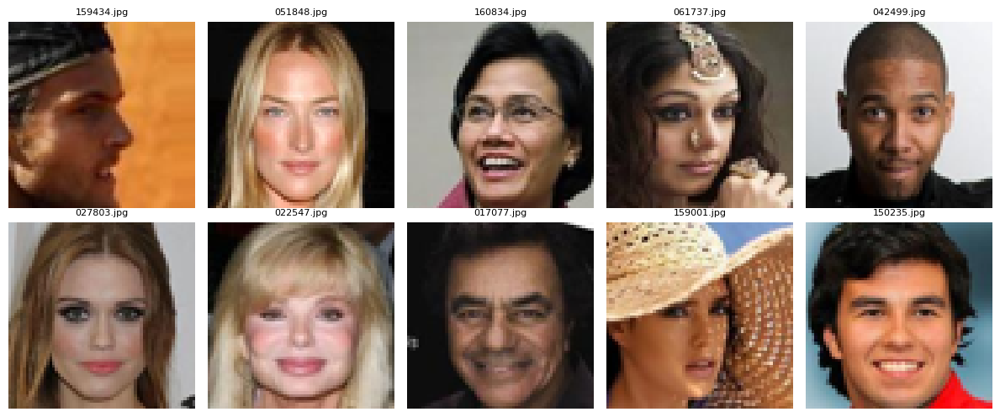

In [8]:
def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))

---

## **3. Encoder, decoder y autoencoder con *Self-Attention* en $8 \times 8$**

Partimos de la arquitectura exacta de `mejora1.ipynb` (incluyendo el *Spatial Bottleneck* `4x4x16`) e insertamos un bloque `SelfAttention2D` únicamente en la resolución **`8x8`**:

- **En el encoder:** tras el bloque de `filters = 128` (`8x8x128`), justo antes de la última compresión a `4x4`.
- **En el decoder:** tras el bloque de `filters = 256` (`8x8x256`), justo después de salir del cuello de botella `4x4`.

Cada bloque `SelfAttention2D` proyecta la entrada mediante convoluciones `1x1` en *Queries* ($C/8$), *Keys* ($C/8$) y *Values* ($C/2$), calcula la matriz de atención escalada $\text{softmax}(Q K^T / \sqrt{d_k})$, la aplica sobre $V$, vuelve al número original de canales con una proyección de salida $W_o$ (`1x1`) y suma la salida ponderada por el escalar entrenable $\gamma$ inicializado en `0`.

In [9]:
@tf.keras.utils.register_keras_serializable(package="MejorasAE")
class SelfAttention2D(layers.Layer):
    def __init__(self, key_divisor=8, value_divisor=2, **kwargs):
        super().__init__(**kwargs)
        self.key_divisor = key_divisor
        self.value_divisor = value_divisor

    def build(self, input_shape):
        channels = input_shape[-1]
        if channels is None:
            raise ValueError("SelfAttention2D necesita conocer el número de canales.")
        channels = int(channels)

        key_dim = max(1, channels // self.key_divisor)
        value_dim = max(1, channels // self.value_divisor)

        self.query_conv = layers.Conv2D(key_dim, kernel_size=1, use_bias=False)
        self.key_conv = layers.Conv2D(key_dim, kernel_size=1, use_bias=False)
        self.value_conv = layers.Conv2D(value_dim, kernel_size=1, use_bias=False)
        self.out_conv = layers.Conv2D(channels, kernel_size=1, use_bias=False)

        self.gamma = self.add_weight(
            name="gamma",
            shape=(),
            initializer="zeros",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs):
        shape = tf.shape(inputs)
        batch, height, width = shape[0], shape[1], shape[2]
        num_tokens = height * width

        q = self.query_conv(inputs)
        k = self.key_conv(inputs)
        v = self.value_conv(inputs)

        q = tf.reshape(q, [batch, num_tokens, self.query_conv.filters])
        k = tf.reshape(k, [batch, num_tokens, self.key_conv.filters])
        v = tf.reshape(v, [batch, num_tokens, self.value_conv.filters])

        scale = tf.math.rsqrt(tf.cast(self.query_conv.filters, q.dtype))
        scores = tf.matmul(q, k, transpose_b=True) * scale
        attention = tf.nn.softmax(scores, axis=-1)

        out = tf.matmul(attention, v)
        out = tf.reshape(out, [batch, height, width, self.value_conv.filters])
        out = self.out_conv(out)

        return inputs + tf.cast(self.gamma, out.dtype) * out

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        config = super().get_config()
        config.update({
            "key_divisor": self.key_divisor,
            "value_divisor": self.value_divisor,
        })
        return config


encoder_inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, CHANNELS),
    name="encoder_input",
)
x = encoder_inputs

for filters in (32, 64, 128, 256):
    x = layers.Conv2D(
        filters,
        kernel_size=4,
        strides=2,
        padding="same",
        use_bias=False,
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    if filters == 128:  # resolución 8x8
        x = SelfAttention2D(name="self_attn_enc_8x8")(x)

z = layers.Conv2D(
    LATENT_CHANNELS,
    kernel_size=1,
    padding="same",
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_spatial",
)(x)

encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()

2026-11-16 20:05:29.882895: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-11-16 20:05:29.882925: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-16 20:05:29.882932: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-11-16 20:05:29.882951: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-16 20:05:29.882969: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ self_attn_enc_8x8               │ (None, 8, 8, 128)      │             1 │
│ (SelfAttention2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 4, 4, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_spatial (Conv2D)         │ (None, 4, 4, 16)       │         4,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 695,697 (2.65 MB)

 Trainable params: 694,737 (2.65 MB)

 Non-trainable params: 960 (3.75 KB)

In [10]:
decoder_inputs = keras.Input(shape=LATENT_SHAPE, name="decoder_input")
x = layers.Conv2D(256, kernel_size=1, padding="same", use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

for filters in (256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    if filters == 256:  # resolución 8x8
        x = SelfAttention2D(name="self_attn_dec_8x8")(x)

decoder_outputs = layers.Conv2D(
    CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
)(x)
decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()

Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 4, 4, 256)      │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ self_attn_dec_8x8               │ (None, 8, 8, 256)      │             1 │
│ (SelfAttention2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 64)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 64, 64, 3)      │           86

 Total params: 984,804 (3.76 MB)

 Trainable params: 983,332 (3.75 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [11]:
autoencoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="autoencoder_input")
autoencoder = keras.Model(
    autoencoder_input,
    decoder_ae(encoder_ae(autoencoder_input)),
    name="autoencoder",
)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 4, 4, 16)       │       695,697 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 3)      │       984,804 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,680,501 (6.41 MB)

 Trainable params: 1,678,069 (6.40 MB)

 Non-trainable params: 2,432 (9.50 KB)

---

## **4. Función de pérdida**

In [12]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

LAMBDA = 1e-4
vgg = keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
vgg.trainable = False
LAYERS = ["block1_conv2", "block2_conv2"]
feat = keras.Model(vgg.input, [vgg.get_layer(name).output for name in LAYERS], name="vgg_features")
feat.trainable = False


def perceptual(y_true, y_pred):
    preprocess = lambda x: keras.applications.vgg16.preprocess_input(x * 255.0)
    true_features = feat(preprocess(y_true), training=False)
    pred_features = feat(preprocess(y_pred), training=False)
    return tf.add_n([
        tf.reduce_mean(tf.abs(true - pred))
        for true, pred in zip(true_features, pred_features)
    ])


def full_loss(y_true, y_pred):
    return ssim_l1_loss(y_true, y_pred) + LAMBDA * perceptual(y_true, y_pred)


INITIAL_LEARNING_RATE = 1e-3
MIN_LEARNING_RATE = 1e-5
DECAY_STEPS = int(np.ceil(len(x_train) / BATCH_SIZE) * EPOCHS)
learning_rate_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=INITIAL_LEARNING_RATE,
    decay_steps=DECAY_STEPS,
    alpha=MIN_LEARNING_RATE / INITIAL_LEARNING_RATE,
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate_schedule),
    loss=full_loss,
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

---

## **5. Entrenamiento**

In [13]:
if TRAIN_MODEL:
    history_ae = autoencoder.fit(
        x_train,
        x_train,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_data=(x_val, x_val),
        callbacks=callbacks,
    )
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    HISTORY_PATH.write_text(json.dumps({
        key: [float(value) for value in values]
        for key, values in history_ae.history.items()
    }, indent=2))
else:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    custom_objs = {
        "SelfAttention2D": SelfAttention2D,
        "ssim_l1_loss": ssim_l1_loss,
        "perceptual": perceptual,
        "full_loss": full_loss,
    }
    autoencoder = keras.models.load_model(AE_PATH, custom_objects=custom_objs)
    encoder_ae = keras.models.load_model(ENCODER_PATH, custom_objects=custom_objs)
    decoder_ae = keras.models.load_model(DECODER_PATH, custom_objects=custom_objs)
    history_ae = type("History", (), {"history": json.loads(HISTORY_PATH.read_text())})()

Epoch 1/30


2026-11-16 20:05:37.959387: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


469/469 ━━━━━━━━━━━━━━━━━━━━ 228s 474ms/step - loss: 0.3168 - val_loss: 0.2295
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 213s 454ms/step - loss: 0.1892 - val_loss: 0.1821
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 212s 452ms/step - loss: 0.1682 - val_loss: 0.1681
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 225s 479ms/step - loss: 0.1581 - val_loss: 0.1611
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 204s 434ms/step - loss: 0.1517 - val_loss: 0.1536
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 210s 448ms/step - loss: 0.1472 - val_loss: 0.1487
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 219s 466ms/step - loss: 0.1437 - val_loss: 0.1450
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 209s 445ms/step - loss: 0.1411 - val_loss: 0.1411
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 209s 446ms/step - loss: 0.1388 - val_loss: 0.1383
Epoch 10/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 211s 450ms/step - loss: 0.1368 - val_loss: 0.1365
Epoch 11/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 208s 444ms/step - loss: 0.1351 - val_loss: 0.1352
Epoch 12/30
469/469

In [14]:
val_losses = history_ae.history["val_loss"]
best_index = int(np.argmin(val_losses))

print(f"Mejor época: {best_index + 1}")
print(f"Loss de entrenamiento: {history_ae.history['loss'][best_index]:.6f}")
print(f"Val loss: {val_losses[best_index]:.6f}")

Mejor época: 30
Loss de entrenamiento: 0.120285
Val loss: 0.122214


La mejora1 de los bloques 1x1 y el latente que conservaba la espacialidad tuvo un resultado algo peor pero muy similar.

---

## **6. Reconstrucciones en test**

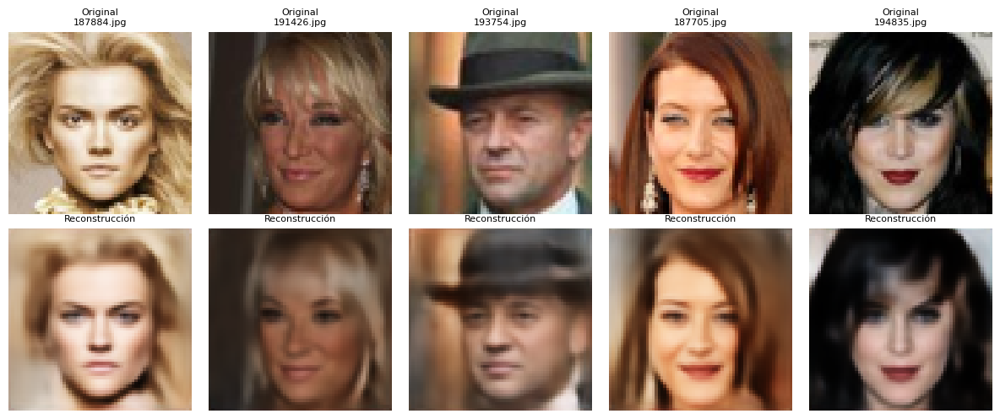

In [15]:
test_indices = sample_rng.choice(len(x_test), size=5, replace=False)
test_reconstructions = autoencoder.predict(x_test[test_indices], verbose=0)
comparison = np.concatenate([x_test[test_indices], test_reconstructions], axis=0)
titles = [f"Original\n{ids_test[i]}" for i in test_indices] + ["Reconstrucción"] * len(test_indices)
show_images(comparison, titles, cols=5, figsize=(12, 5))

Mejor época según val_loss: 30


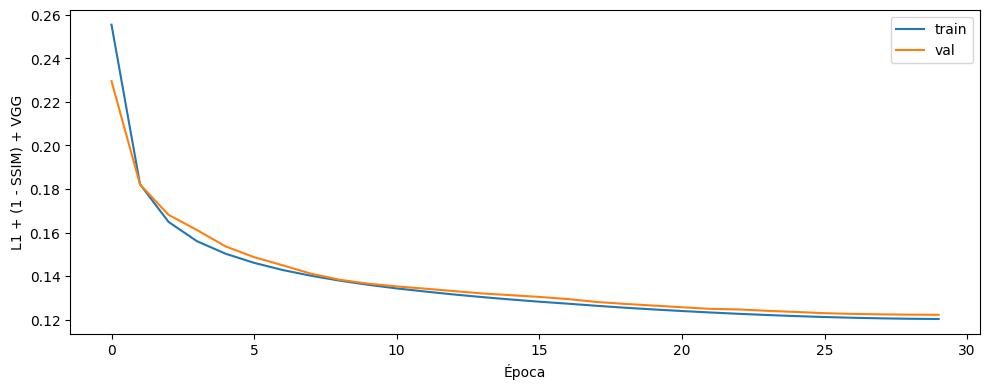

In [16]:
if hasattr(history_ae, "history") and "val_loss" in history_ae.history:
    best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
    print(f"Mejor época según val_loss: {best_epoch}")
    plt.figure(figsize=(10, 4))
    plt.plot(history_ae.history["loss"], label="train")
    plt.plot(history_ae.history["val_loss"], label="val")
    plt.xlabel("Época")
    plt.ylabel("L1 + (1 - SSIM) + VGG")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [17]:
# FID de reconstrucciones y preparación para el FID del morphing
# El FID compara distribuciones de imágenes; por eso se usa un conjunto de test.
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_REAL_SAMPLES = min(1000, len(x_test))
FID_BATCH_SIZE = 32


def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se esperaban imágenes con forma (N, H, W, 1|3); recibidas {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    return float(fid.compute().item())

In [18]:
fid_reconstruction_images = x_test[:FID_REAL_SAMPLES]
fid_reconstruction_reference = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]
reconstructed_test_images = autoencoder.predict(
    fid_reconstruction_images,
    batch_size=FID_BATCH_SIZE,
    verbose=0,
)
reconstruction_fid = calculate_fid(
    reconstructed_test_images,
    fid_reconstruction_reference,
)
print(f"FID de reconstrucciones ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

FID de reconstrucciones (1000 imágenes): 60.5282


El FID mejora 1 punto respecto a `mejora1.ipynb`, por lo que ahora si podemos decir que el resultado ha mejorado realmente.

---

## **7. FID y morphing mediante interpolación en el espacio latente**

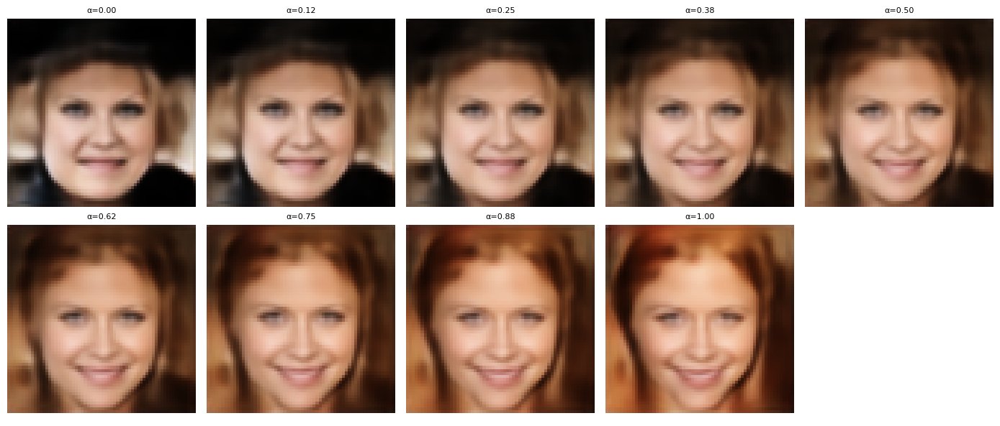

A: 182638.jpg | B: 182640.jpg


In [19]:
def morph_images(image_a, image_b, steps=9):
    if image_a.shape != image_b.shape:
        raise ValueError(f"Las imágenes deben tener la misma forma; recibidas {image_a.shape} y {image_b.shape}")
    z_a = encoder_ae.predict(image_a[None, ...], verbose=0)[0]
    z_b = encoder_ae.predict(image_b[None, ...], verbose=0)[0]
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)
    latent_path = (1.0 - alphas[:, None, None, None]) * z_a + alphas[:, None, None, None] * z_b
    return alphas, decoder_ae.predict(latent_path, verbose=0)

morph_a_index, morph_b_index = 0, 1
alphas, morph_sequence = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9)
show_images(
    morph_sequence,
    [f"α={alpha:.2f}" for alpha in alphas],
    cols=5,
    figsize=(14, 6),
)
print(f"A: {ids_test[morph_a_index]} | B: {ids_test[morph_b_index]}")

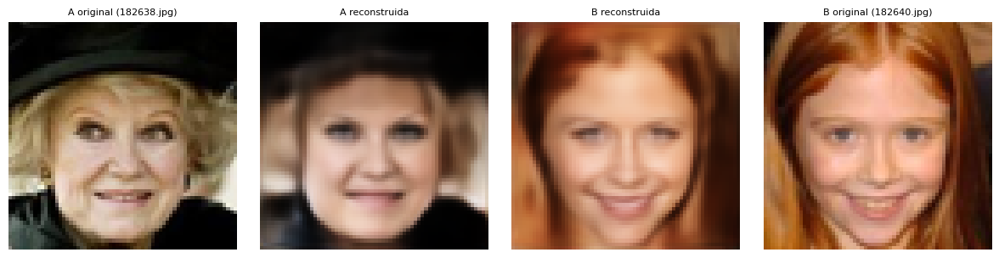

In [20]:
# Comparación de extremos: original frente a reconstrucción usada en la interpolación.
endpoints = np.stack([
    x_test[morph_a_index], morph_sequence[0],
    morph_sequence[-1], x_test[morph_b_index],
])
show_images(
    endpoints,
    [f"A original ({ids_test[morph_a_index]})", "A reconstruida", "B reconstruida", f"B original ({ids_test[morph_b_index]})"],
    cols=4,
    figsize=(12, 3),
)

---

## **8. Secuencia visual y GIF del morphing**

In [21]:
GIF_PATH = PROCESSED_DIR.parent.parent / "gif" / "fusion_mejora3_selfattn256_morphing.gif"
N_FRAMES = 80
FRAME_MS = 50

z_a = encoder_ae.predict(
    x_test[morph_a_index][None, ...],
    verbose=0,
)[0]
z_b = encoder_ae.predict(
    x_test[morph_b_index][None, ...],
    verbose=0,
)[0]

alphas = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)
z_frames = (1.0 - alphas[:, None, None, None]) * z_a + alphas[:, None, None, None] * z_b

decoded = decoder_ae.predict(z_frames, verbose=0)

GIF guardado en '/Users/dani22/Desktop/ProyectoCD/morphing/gif/fusion_mejora3_selfattn256_morphing.gif' | 80 fotogramas


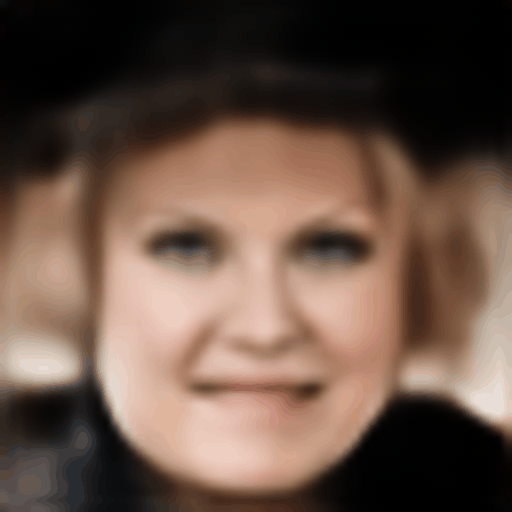

In [22]:
frames = [
    Image.fromarray((np.clip(image, 0, 1) * 255).astype(np.uint8))
    .resize((512, 512), Image.Resampling.BICUBIC)
    for image in decoded
]

gif_path = Path(GIF_PATH).resolve()
gif_path.parent.mkdir(parents=True, exist_ok=True)
if not frames:
    raise RuntimeError("No se generaron fotogramas para el GIF")

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=FRAME_MS,
    loop=0,
)

print(f"GIF guardado en '{gif_path}' | {len(frames)} fotogramas")
display(IPyImage(filename=str(gif_path)))

---

## **9. Decisiones de diseño y comparativa con `mejora1` y `mejora2`**

Hemos mejorado el FID algo menos que en `mejora2.ipynb`, aunque la diferencia es mínima. Lo que ha quedado claro es que ambos métodos, junto con el espacio latente espacial, funcionan y permiten mejorar la generación intermedia del morphing. 

Como ya explicamos anteriormente, podríamos realizar miles de pruebas con distintas combinaciones de atención, pero el objetivo de este bloque del proyecto es **demostrar que la atención global y la espacialidad del latente son útiles para mejorar la coherencia y simetría del morphing**. 

Dicho esto, es momento de pasar a los bloques 5 y 6 explicados en `explicacion_mejoras.ipynb`, donde probaremos la fusión del modelo autoencoder con una GAN que nos ayude a mejorar los resultados.